# Chapter 9 — Modeling Probabilities and Nonlinearities: Activation Functions

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 9, explain every theory, and reproduce the code (activation functions, softmax, cross-entropy, a tanh + softmax network).

> ⚙️ **Dataset note:** as in Chapter 8 we use scikit-learn's offline `load_digits` (8×8 images, with σ = 0.35 pixel noise) instead of downloading MNIST. Here we train on **300** images and test on the remaining 1 497.

---

## 1. Chapter Summary

An **activation function** is a function applied to the neurons of a layer during prediction. Chapter 9 explains *what makes a good one* and shows how to turn a network's raw outputs into **probabilities**.

1. **What is an activation function?** A non-linear function applied element-wise to a layer's weighted sum (e.g. `relu`, `sigmoid`, `tanh`).
2. **Constraints for a valid activation function**
   1. It must be **continuous and infinite in domain** (any input gives an output, no gaps).
   2. It should be **monotonic** (always increasing or always decreasing) — otherwise one output value could map to multiple inputs, hurting learning.
   3. It must be **non-linear** (not a straight line) so that it can create *selective correlation*.
   4. It should be **efficiently computable** (also its derivative).
3. **Standard hidden-layer activations:** 
   * **sigmoid** — squashes to (0, 1); a smooth "probability-like on/off switch";
   * **tanh** — squashes to (−1, 1); *negative correlation* is representable, usually better than sigmoid in hidden layers (it makes values zero-centred and lets nodes "turn off" for some inputs and "invert" for others);
   * **relu** — `max(0, x)`; the default in modern networks.
4. **Standard output-layer activations** depend on the task:
   * predicting **raw numbers** → *no* activation;
   * predicting **unrelated yes/no probabilities** → **sigmoid** per output;
   * predicting **which ONE of several** classes → **softmax**.
5. **Softmax** converts a vector of raw scores into a probability distribution (positive, sums to 1). It models "pick exactly one" and creates *competition* among the outputs.
6. **Cross-entropy loss** (or "negative log likelihood") is the natural loss for softmax: it directly penalises the log of the probability given to the correct class. The gradient simplifies to the same easy form as before: `delta = prediction − target`.
7. **The MNIST/digits network is rebuilt with tanh + softmax + dropout + mini-batches**, giving probability outputs and accuracy comparable to the ReLU/MSE version.
8. **Upgrading the book's earlier delta rule:** the derivative of tanh is `1 − output²`, of sigmoid `output·(1 − output)`, of relu `output > 0`. Each hidden-layer delta gets multiplied by this local derivative.

---

## 2. Theory Deep-Dive

### 2.1 Why we need non-linear activations
Without them, stacked layers are one linear map (Ch. 6). The activation gives a node the ability to be **selectively correlated** with the output: e.g. *relu* ignores negative evidence, *tanh/sigmoid* saturate for very large evidence.

### 2.2 The three classical functions

| Function | Formula | Range | Derivative (from output $o$) |
|---|---|---|---|
| sigmoid | $\sigma(x)=\dfrac1{1+e^{-x}}$ | (0, 1) | $o(1-o)$ |
| tanh | $\tanh x=\dfrac{e^{x}-e^{-x}}{e^{x}+e^{-x}}$ | (−1, 1) | $1-o^2$ |
| relu | $\max(0,x)$ | [0, ∞) | $1$ if $o>0$ else $0$ |

* **sigmoid** (0-1) is ideal as an *output* for independent probabilities. It saturates (slope ≈ 0 at the extremes → slow learning).
* **tanh** gives both positive *and negative* values, so hidden nodes can *vote against* as well as for; zero-centred values speed up learning relative to sigmoid.
* **relu** has no saturation for positive values; cheap and effective.

### 2.3 Softmax
Given raw scores $z_k$ ("logits"):
$$p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$
* *Exponentiation* makes every score positive and amplifies differences (bigger score → *much* bigger probability).
* *Normalisation* makes the vector sum to 1.
* Raising one output's score **lowers all the others** — there's a competition for the single probability mass, ideal for "exactly one class is correct".

Numerical stability: subtract $\max(z)$ before exponentiating (doesn't change the result).

### 2.4 Cross-entropy loss
For one-hot target $y$ and softmax output $p$:
$$L=-\sum_k y_k\log p_k = -\log p_{correct}$$
* If the correct class gets probability ≈ 1 → loss ≈ 0; probability → 0 gives loss → ∞ — a *strong* push where MSE would give a feeble gradient.
* **Gradient w.r.t. the logits is simply** $\dfrac{\partial L}{\partial z}=p-y$. That is the same "pure error" `delta = pred − target` as in all earlier chapters, which is why softmax + cross-entropy is so convenient.

### 2.5 Matching the activation to the problem

| Output you predict | Output activation | Loss |
|---|---|---|
| a real number | none (linear) | MSE |
| several independent yes/no | sigmoid | binary cross-entropy |
| exactly one of K classes | **softmax** | **cross-entropy** |

### 2.6 Tanh in the hidden layer — what changes in the code
* forward: `layer_1 = tanh(layer_0 · W0)`
* backward: `layer_1_delta = (layer_2_delta · W1ᵀ) × (1 − layer_1²)`
* weights initialised **smaller** (e.g. ±0.01) to avoid saturating `tanh` immediately.

---

## 3. Code Reproduction

### 3.1 Visualising activation functions and their derivatives

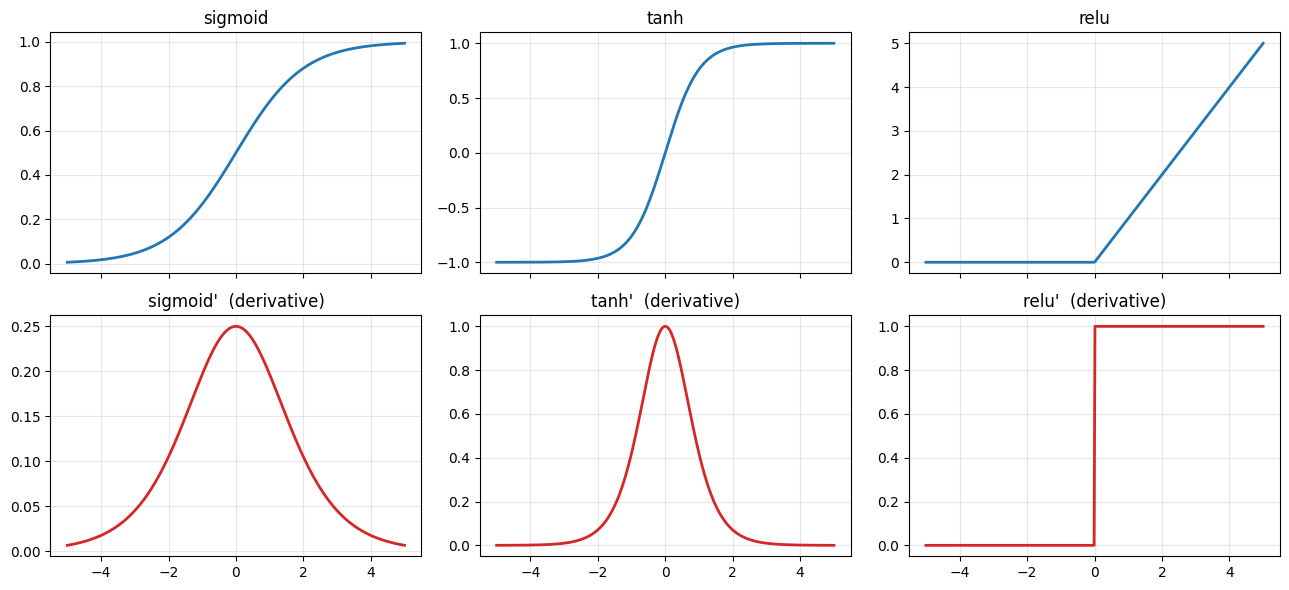

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.datasets import load_digits
os.makedirs("folder-picture", exist_ok=True)

x = np.linspace(-5, 5, 400)
sigmoid = lambda v: 1 / (1 + np.exp(-v))
relu    = lambda v: np.maximum(0, v)

acts = {
    "sigmoid": (sigmoid(x), sigmoid(x) * (1 - sigmoid(x))),
    "tanh":    (np.tanh(x), 1 - np.tanh(x) ** 2),
    "relu":    (relu(x),    (x > 0).astype(float)),
}
fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for k, (name, (f, df)) in enumerate(acts.items()):
    ax[0, k].plot(x, f, lw=2); ax[0, k].set_title(name); ax[0, k].grid(alpha=.3)
    ax[1, k].plot(x, df, lw=2, c="tab:red"); ax[1, k].set_title(f"{name}'  (derivative)"); ax[1, k].grid(alpha=.3)
plt.tight_layout()
plt.savefig("folder-picture/ch09_activation_functions.png", dpi=120, bbox_inches="tight")
plt.show()

Note how **sigmoid'** never exceeds 0.25 and vanishes in both tails (saturation), **tanh'** peaks at 1, and **relu'** is exactly 1 for any positive input.

### 3.2 Softmax in code (with the max-subtraction trick) and the effect of exponentiation

raw scores       : [1. 2. 3. 4.]
softmax          : [0.032 0.087 0.237 0.644]  sum = 1.0
raw 'normalised' : [0.1 0.2 0.3 0.4]  <- just dividing by the sum is much flatter
score of node 3 = 2 -> probs [0.333 0.333 0.333]
score of node 3 = 3 -> probs [0.212 0.212 0.576]
score of node 3 = 4 -> probs [0.107 0.107 0.787]
score of node 3 = 5 -> probs [0.045 0.045 0.909]


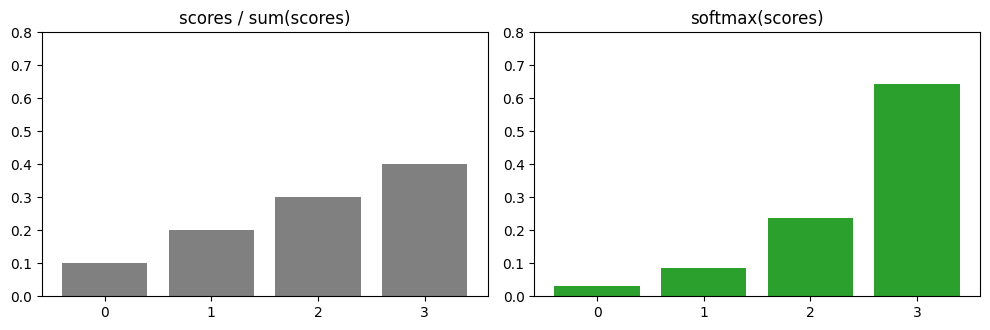

In [2]:
def softmax(z):
    e = np.exp(z - z.max(axis=-1, keepdims=True))      # numerical stability
    return e / e.sum(axis=-1, keepdims=True)

scores = np.array([1.0, 2.0, 3.0, 4.0])
print("raw scores       :", scores)
print("softmax          :", softmax(scores).round(3), " sum =", softmax(scores).sum())
print("raw 'normalised' :", (scores / scores.sum()).round(3), " <- just dividing by the sum is much flatter")

# Competition: raise one score and the others drop
for bump in (0, 1, 2, 3):
    s = np.array([2.0, 2.0, 2.0 + bump])
    print(f"score of node 3 = {s[2]:.0f} -> probs {softmax(s).round(3)}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(range(4), scores / scores.sum(), color="gray"); ax[0].set_title("scores / sum(scores)")
ax[1].bar(range(4), softmax(scores), color="tab:green"); ax[1].set_title("softmax(scores)")
for a in ax: a.set_xticks(range(4)); a.set_ylim(0, 0.8)
plt.tight_layout()
plt.savefig("folder-picture/ch09_softmax.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.3 Cross-entropy and its gradient `p − y`

We verify numerically that the analytic gradient of cross-entropy w.r.t. the logits equals `softmax(z) − y`.

In [3]:
def cross_entropy(z, y_onehot):
    return -np.sum(y_onehot * np.log(softmax(z) + 1e-12))

z = np.array([0.5, -1.0, 2.0, 0.1])
y = np.array([0, 0, 1, 0])
analytic = softmax(z) - y

numeric = np.zeros_like(z)
eps = 1e-6
for i in range(len(z)):
    zp, zm = z.copy(), z.copy(); zp[i] += eps; zm[i] -= eps
    numeric[i] = (cross_entropy(zp, y) - cross_entropy(zm, y)) / (2 * eps)

print("analytic  p - y :", analytic.round(6))
print("numerical grad  :", numeric.round(6))
print("max |difference|:", np.abs(analytic - numeric).max())

analytic  p - y : [ 0.156859  0.035    -0.297005  0.105146]
numerical grad  : [ 0.156859  0.035    -0.297005  0.105146]
max |difference|: 1.321056597447523e-10


### 3.4 Data (same preparation as Chapter 8, 300 training images)

In [4]:
digits = load_digits()
X_all = digits.data / 16.0
y_all = digits.target
X_all = np.clip(X_all + np.random.default_rng(5).normal(0, 0.35, X_all.shape), 0, 1)

perm = np.random.default_rng(0).permutation(len(X_all))
N_TRAIN = 300
tr, te = perm[:N_TRAIN], perm[N_TRAIN:]
x_train, y_train = X_all[tr], y_all[tr]
x_test,  y_test  = X_all[te], y_all[te]
labels_train = np.eye(10)[y_train]
print("train", x_train.shape, " test", x_test.shape)

train (300, 64)  test (1497, 64)


### 3.5 Network with **tanh** hidden layer, **softmax** output, **dropout**, **mini-batches**

This is the book's final network of the chapter: `l1 = tanh(l0 W0)`, dropout mask on `l1`, `l2 = softmax(l1 W1)`, `d2 = (l2 − y)/batch`, `d1 = d2 W1ᵀ × (1 − l1²) × mask`.

In [5]:
tanh2deriv = lambda output: 1 - output ** 2

def train_tanh_softmax(batch_size=20, alpha=0.1, hidden=200, epochs=100, seed=1):
    r = np.random.default_rng(seed)
    W0 = 0.02 * r.random((64, hidden)) - 0.01          # small init: avoids saturating tanh
    W1 = 0.2  * r.random((hidden, 10)) - 0.1
    tr_acc, te_acc, losses = [], [], []
    for epoch in range(epochs):
        ep_loss = 0.0
        for s in range(0, N_TRAIN, batch_size):
            l0 = x_train[s:s + batch_size]
            y  = labels_train[s:s + batch_size]
            l1 = np.tanh(l0 @ W0)
            mask = r.integers(0, 2, size=l1.shape) * 2          # dropout (x2 scaling folded in)
            l1d = l1 * mask
            l2 = softmax(l1d @ W1)
            ep_loss += -np.sum(y * np.log(l2 + 1e-12))
            d2 = (l2 - y) / len(l0)
            d1 = (d2 @ W1.T) * tanh2deriv(l1) * mask
            W1 -= alpha * l1d.T @ d2
            W0 -= alpha * l0.T @ d1
        pred_tr = (np.tanh(x_train @ W0) @ W1).argmax(1)
        pred_te = (np.tanh(x_test  @ W0) @ W1).argmax(1)
        tr_acc.append((pred_tr == y_train).mean()); te_acc.append((pred_te == y_test).mean())
        losses.append(ep_loss / N_TRAIN)
    return np.array(tr_acc), np.array(te_acc), np.array(losses), (W0, W1)

tr_a, te_a, loss_a, (W0, W1) = train_tanh_softmax()
print(f"tanh+softmax : train acc {tr_a[-1]:.3f} | test acc {te_a[-1]:.3f} | cross-entropy {loss_a[-1]:.4f}")

tanh+softmax : train acc 1.000 | test acc 0.746 | cross-entropy 0.0655


### 3.6 Comparison: relu + MSE (Chapter 8 style) vs. tanh + softmax (Chapter 9 style)

relu + MSE      : final train 0.994  final test 0.761  (best test 0.761)
tanh + softmax  : final train 1.000  final test 0.746  (best test 0.780)


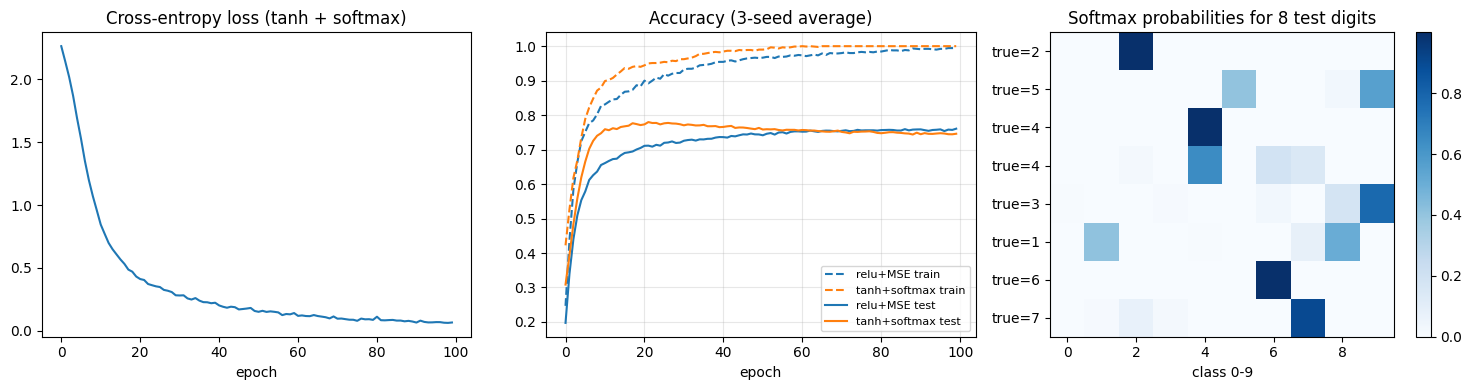

In [6]:
def train_relu_mse(batch_size=20, alpha=0.05, hidden=200, epochs=100, seed=1):
    r = np.random.default_rng(seed)
    W0 = 0.2 * r.random((64, hidden)) - 0.1
    W1 = 0.2 * r.random((hidden, 10)) - 0.1
    tr_acc, te_acc = [], []
    for epoch in range(epochs):
        for s in range(0, N_TRAIN, batch_size):
            l0 = x_train[s:s + batch_size]; y = labels_train[s:s + batch_size]
            h = np.maximum(0, l0 @ W0)
            mask = r.integers(0, 2, size=h.shape) * 2
            l1 = h * mask
            l2 = l1 @ W1
            d2 = (l2 - y) / len(l0)
            d1 = (d2 @ W1.T) * (h > 0) * mask
            W1 -= alpha * l1.T @ d2
            W0 -= alpha * l0.T @ d1
        tr_acc.append(((np.maximum(0, x_train @ W0) @ W1).argmax(1) == y_train).mean())
        te_acc.append(((np.maximum(0, x_test  @ W0) @ W1).argmax(1) == y_test).mean())
    return np.array(tr_acc), np.array(te_acc)

seeds = (1, 2, 3)
A = [train_tanh_softmax(seed=s) for s in seeds]
B = [train_relu_mse(seed=s) for s in seeds]
te_tanh = np.mean([a[1] for a in A], axis=0);  tr_tanh = np.mean([a[0] for a in A], axis=0)
te_relu = np.mean([b[1] for b in B], axis=0);  tr_relu = np.mean([b[0] for b in B], axis=0)

print(f"relu + MSE      : final train {tr_relu[-1]:.3f}  final test {te_relu[-1]:.3f}  (best test {te_relu.max():.3f})")
print(f"tanh + softmax  : final train {tr_tanh[-1]:.3f}  final test {te_tanh[-1]:.3f}  (best test {te_tanh.max():.3f})")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(loss_a); ax[0].set_title("Cross-entropy loss (tanh + softmax)"); ax[0].set_xlabel("epoch")
ax[1].plot(tr_relu, label="relu+MSE train", ls="--", c="tab:blue"); ax[1].plot(tr_tanh, label="tanh+softmax train", ls="--", c="tab:orange")
ax[1].plot(te_relu, label="relu+MSE test", c="tab:blue"); ax[1].plot(te_tanh, label="tanh+softmax test", c="tab:orange")
ax[1].set_title("Accuracy (3-seed average)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

probs = softmax(np.tanh(x_test[:8] @ W0) @ W1)
im = ax[2].imshow(probs, cmap="Blues", aspect="auto")
ax[2].set_title("Softmax probabilities for 8 test digits"); ax[2].set_xlabel("class 0-9")
ax[2].set_yticks(range(8)); ax[2].set_yticklabels([f"true={t}" for t in y_test[:8]])
plt.colorbar(im, ax=ax[2])
plt.tight_layout()
plt.savefig("folder-picture/ch09_tanh_softmax_training.png", dpi=120, bbox_inches="tight")
plt.show()

Softmax makes the network output a **probability distribution** per image (right plot) — confident when the digit is clean, spread over several classes when it is ambiguous. In accuracy, tanh + softmax and relu + MSE end up **comparable** on this small noisy dataset (within about 1-2 points; which one is slightly ahead changes with the seed and the epoch). The real advantage of softmax + cross-entropy is not raw accuracy here but that the outputs are **interpretable probabilities** and the loss/gradient (`p − y`) has the right shape for classification.

---

## 4. Key Takeaways

* A good activation function is **continuous, monotonic, non-linear and cheap**; the derivative is needed for backprop (`tanh' = 1 − o²`, `sigmoid' = o(1−o)`, `relu' = o>0`).
* **Hidden layers:** relu / tanh (tanh can express negative correlation); **output layer:** pick by task — none, sigmoid, or **softmax**.
* **Softmax** = exponentiate + normalise → a distribution that sums to 1 with competition between classes.
* **Cross-entropy** pairs with softmax and yields the clean gradient `delta = p − y`.
* Use **smaller initial weights** with tanh, plus dropout and mini-batches from Chapter 8.

➡️ **Next:** Chapter 10 — **convolutional neural networks**: reuse the *same* small detector everywhere in the image.